# Supplementary Figure 3.5: Conditional accuracy functions, OL vs. MX blocks 1–3

The **conditional accuracy function (CAF)** from the collapsing-bound
literature (e.g. Ditterich 2006, *Eur J Neurosci*): the probability that a
decision terminating at time `t` (here, decision time `DT = t`, in steps)
lands on the rewarded side, `P(correct | DT = t)`, plotted against `t`. This
is not overall accuracy — it conditions specifically on trials that took
exactly `t` steps to decide.

Trial-to-trial variability in drift rate and in bound height make opposite
predictions for the shape of this function:

- **Drift rate varies trial to trial, bound is fixed**: slow-terminating
  trials become progressively enriched for the harder (lower-|SNR|) trials —
  the easy trials have mostly already terminated by then — so CAF should
  **decline** with `t`.
- **Bound also varies trial to trial** (this paper's "flexible decision rule"
  account): extra, SNR-independent trial-to-trial bound variability broadens
  the bound crossed at any given `t`, diluting the low-SNR-enrichment effect
  above, so CAF should be **flatter, or rise**, relative to the fixed-bound
  case.

This notebook computes the CAF for both task types, restricted to **blocks
1–3** (raw 6-block numbering, same block/dataset convention as
`Table_slopeAnalyses`):

- **Top row: OL (blocked SNR)**. A single SNR level per block, so any
  trial-to-trial drift variability the model exhibits comes only from the
  bound-estimation/step-noise pipeline, not from a deliberately varying
  generative SNR.
- **Bottom row: MX (mixed SNR)**. Two SNR levels (lo = 1/3, hi = 1)
  interleaved trial by trial within a block, so drift rate genuinely varies
  from trial to trial by design and subjects cannot know in advance which SNR
  applies on a given trial — the natural place to test the drift-varies null
  directly. This is the analysis formerly in `Figure05_S03` (removed), now
  paired with the OL version formerly in `Figure03S04_sequentialAnalysis`
  Part 4 (also removed) so the two task types can be compared side by side.

For each block and task, the empirical CAF (pooled across subjects, `DT` =
3–10 steps — the range with enough pooled trials to be stable) is fit with a
**bound-SD model**: each subject's own median |bound| in that block
(`bound_type='var'` in `get_simulated_data_table`, matched to each subject's
own generative SNR(s), as in the earlier fixed/variable-bound simulations),
but with the per-trial bound SD replaced by a single free parameter
(`var_bound_std`) shared across all subjects in that panel. This parameter is
fit by minimizing the weighted squared error between the model's pooled
per-`DT` accuracy and the real per-`DT` accuracy (weights = real trial counts
per `DT` bin) — i.e. the amount of subject-shared bound variability, in bound
units, that best explains the shape of the real CAF. The model is then
simulated `N_REPS` times per subject at the fitted SD and pooled; a linear
regression of `correct ~ DT` (pooled trials, restricted to `DT_VALS`) through
this pooled model gives the fitted line plotted against the real data below,
annotated with the fitted SD, slope (β), and p-value.

This replaces an earlier version of this analysis that separately simulated
a fixed-bound model (`bound_type='fixed'`, no trial-to-trial bound
variability) and a variable-bound model using each subject's own *empirical*
bound SD, and compared both against the real data's own plain linear-regression
fit. Rather than asking whether subjects' literal bound variability is
enough to explain the CAF shape, this version asks how much shared bound
variability (as a single free parameter) the real CAF itself implies, and
uses that best-fit amount as the model.

**Adaptation-based trial exclusion**: for subjects with a *good* within-block
adaptation time constant (τ) fit in a given block and task — same eligibility
and censoring criteria as the τ insets in `Figure04_RRvsBound` panels D–F
(`pigeon.adaptation.get_adaptation_tau_fits`), i.e. tau-fit eligible and
converged before the 40-trial fit window (not censored, τ < 40) — trials with
`trial_number < τ` are excluded from that subject's data in that block, on
top of the standard quality filters. Subjects without a good fit are
unaffected. Tau fits are computed separately for OL and MX (each task's own
adaptation dynamics), then applied identically to real and simulated trials.

Per-block, per-task numeric summaries are printed; a single combined 2×3
figure (rows = task, columns = blocks) shows the CAF panels. Saves to
`Figure03_S05.pdf`.

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import scipy.stats
import scipy.optimize
import matplotlib.pyplot as plt

from pigeon.data import get_data_table, get_good_trial_array
from pigeon.simulate import get_simulated_data_table
from pigeon.adaptation import get_adaptation_tau_fits
from pigeon.pathDefaults import FIGURES_DIR
from pigeon.plotting import FONT_RC, add_panel_label

plt.rcParams.update(FONT_RC)

## Load data (OL and MX, blocks 1–3)

Raw 6-block numbering (`combine_snr=False`) for both tasks, restricted below
to `BLOCKS = [1, 2, 3]` — the same convention `Figure03S04_sequentialAnalysis`
used for OL, applied here to MX as well so both tasks are read the same way.

In [2]:
BLOCKS = [1, 2, 3]  # raw 6-block numbering, same convention as Table_slopeAnalyses

data_table_ol = get_data_table(task_type='OL', combine_snr=False)
data_table_mx = get_data_table(task_type='MX', combine_snr=False)

  1: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_14h39.24.096.csv
  2: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_15h37.48.260.csv
  3: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h34.46.761.csv
  4: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h35.25.285.csv
  5: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h36.33.669.csv
  6: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h36.41.364.csv
  7: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_16h36.49.086.csv
  8: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 14: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_17h35.53.048.csv
 15: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_17h48.56.013.csv
 16: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_19h38.38.956.csv
 17: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h36.04.663.csv
 18: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h36.05.544.csv
 19: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h36.07.852.csv
 20: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h37.13.084.csv
 21: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 27: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h39.37.708.csv
 28: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h40.06.581.csv
 29: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h41.15.620.csv
 30: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h42.16.563.csv
 31: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h46.46.975.csv
 32: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_22h54.23.759.csv
 33: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h30.52.958.csv
 34: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 40: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h37.41.349.csv
 41: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h38.40.806.csv
 42: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h38.40.851.csv
 43: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h39.13.059.csv
 44: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h41.40.441.csv
 45: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h42.52.039.csv
 46: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-21_23h42.54.723.csv
 47: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 52: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_24h37.16.053.csv
 53: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_24h37.20.203.csv
 54: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_24h37.32.380.csv
 55: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_24h37.37.464.csv
 56: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_24h38.28.207.csv
 57: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_24h39.12.114.csv
 58: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_OL/prolificcsvs/PigeonTask_2022-11-22_24h40.02.817.csv
 59: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

  1: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_09h13.45.625.csv
  2: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_10h11.56.537.csv
  3: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_10h12.28.806.csv
  4: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_10h13.05.149.csv
  5: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_10h13.09.605.csv
  6: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_10h13.30.507.csv
  7: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_10h13.32.506.csv
  8: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 14: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_16h11.54.094.csv
 15: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_16h12.16.148.csv
 16: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_16h12.31.520.csv
 17: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_16h12.41.484.csv
 18: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_16h14.52.557.csv
 19: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_16h18.44.254.csv
 20: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_16h19.33.518.csv
 21: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 26: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_17h12.25.391.csv
 27: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_17h12.29.789.csv
 28: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_17h12.43.591.csv
 29: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_17h12.53.031.csv
 30: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_17h13.00.949.csv
 31: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_17h13.12.054.csv
 32: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_17h13.15.803.csv
 33: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 38: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_17h14.12.270.csv
 39: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_17h19.47.420.csv
 40: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_17h21.56.825.csv
 41: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_17h23.15.258.csv
 42: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_17h23.37.400.csv
 43: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_17h29.44.495.csv
 44: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_18h13.06.340.csv
 45: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

 51: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_18h18.34.289.csv
 52: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_18h18.42.215.csv
 53: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_18h18.52.475.csv
 54: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_18h19.57.520.csv
 55: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_18h26.10.569.csv
 56: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_18h49.58.399.csv
 57: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pigeon/Data/Pigeon_MX/prolificcsvs/PigeonTask_2022-11-23_18h53.32.854.csv
 58: /Users/jigold/GoldWorks/Mirror_jigold/Manuscripts/2023_Pi

## Adaptation-based trial exclusion (per task)

Fits within-block adaptation τ per subject per block for each task using
`pigeon.adaptation.get_adaptation_tau_fits` — the same pipeline, eligibility
criteria, and 40-trial fit window as the τ insets in `Figure04_RRvsBound`
panels D–F. `good_tau_ol` / `good_tau_mx` hold the fitted τ only for "good"
fits (eligible, converged before the 40-trial window, i.e. not censored); NaN
elsewhere. `make_tau_exclusion_mask` builds a keep-mask function for a given
task's `good_tau` table: trials with `trial_number < ceil(τ)` are dropped for
subjects with a good fit in that block; all other subjects/trials are kept
unchanged.

In [3]:
tau_fits_ol = get_adaptation_tau_fits(data_table_ol, blocks=BLOCKS, max_trial=40)
tau_fits_mx = get_adaptation_tau_fits(data_table_mx, blocks=BLOCKS, max_trial=40)
good_tau_ol = tau_fits_ol['good_tau']  # subject x block, NaN unless a good (uncensored) fit
good_tau_mx = tau_fits_mx['good_tau']

for task, tau_fits, good_tau in [('OL', tau_fits_ol, good_tau_ol), ('MX', tau_fits_mx, good_tau_mx)]:
    n_good = good_tau.notna().sum()
    n_total = np.sum(np.any(np.isfinite(tau_fits['real_curves']), axis=1), axis=0)
    print(f'Subjects with a good tau fit, {task}, by block:')
    for bi, b in enumerate(BLOCKS):
        print(f'  Block {b}: {int(n_good[b])}/{int(n_total[bi])}')


def make_tau_exclusion_mask(good_tau):
    """Build a keep-mask function dropping trials with trial_number < ceil(tau)
    for subjects with a good tau fit in that block; True (no exclusion) for
    everyone else."""
    def _mask(df, block):
        keep = pd.Series(True, index=df.index)
        for subj, tau in good_tau[block].dropna().items():
            drop = (df['subject_index'] == subj) & (df['trial_number'] < np.ceil(tau))
            keep &= ~drop
        return keep
    return _mask


tau_mask_ol = make_tau_exclusion_mask(good_tau_ol)
tau_mask_mx = make_tau_exclusion_mask(good_tau_mx)

Subjects with a good tau fit, OL, by block:
  Block 1: 15/58
  Block 2: 27/60
  Block 3: 8/59
Subjects with a good tau fit, MX, by block:
  Block 1: 14/60
  Block 2: 13/60
  Block 3: 15/58


## Parameters and helper functions

**`MIN_DT`**: pre-filter `DT > 2` (keeps DT ≥ 3), matching the convention used
in `Figure05_mixedVsBlockedSNR` and its supplements.

**`DT_VALS`**: DT = 3–10 steps. Chosen empirically: every block/task has
enough pooled trials at every DT in this range (`MIN_POOLED_N`), and counts
fall off sharply beyond DT=10 — this is the stable, well-sampled range
analyzed below.

**`N_REPS`**: number of independent simulated-block replicates per subject,
pooled to smooth out simulation noise while preserving the same finite-block
structure as the real data, used to build the final model CAF at the fitted
bound SD.

**`N_REPS_FIT`, `FIT_SEED`, `SD_BOUNDS`, `SD_XATOL`**: settings for the
bound-SD optimization below. `N_REPS_FIT` (replicates per objective
evaluation during the SD search) needs to be *larger* than `N_REPS`, not
smaller: the objective's sensitivity to SD is much shallower in the
lower-trial-count blocks (block 3 in particular), so too few replicates lets
simulation noise dominate the true, shallow signal and the optimizer locks
onto a spuriously large or small SD. `FIT_SEED` reseeds the RNG identically
on every evaluation of the objective (common random numbers), so the same
underlying trial draws are reused across candidate SD values, which further
smooths the objective on top of the higher replicate count. `SD_BOUNDS` is
the search range for the free bound-SD parameter (empirical per-subject
bound SDs across all blocks/tasks range ~0.15–0.29, so this comfortably
brackets the plausible optimum without hitting either edge). `SD_XATOL` is
the convergence tolerance on the fitted SD.

**`good_dt_correct`**: `DT`/`correct` columns for good trials in one
block, with a task's tau-exclusion mask applied.

**`dt_counts`**: pooled (n_trials, n_correct) per DT bin.

**`clopper_pearson`**: 50% CI (25th/75th percentile of the beta posterior) on
the pooled proportion at each DT bin — same convention as Figure02/Figure03's
accuracy error bars.

**`dt_slope`**: trial-level linear regression (`scipy.stats.linregress`) of
`correct` on `DT`, restricted to `DT_VALS`. Applied to the pooled model CAF
(at the fitted bound SD) below; the sign and significance of the slope is the
direct test of "CAF rises vs. falls," and the fitted line is what's drawn in
the figure below.

In [4]:
MIN_DT         = 2                       # keep DT > 2 (i.e. DT >= 3)
DT_VALS        = np.arange(3, 11)        # DT = 3-10 steps: stable, well-sampled range
MIN_POOLED_N   = 20                      # min real pooled trials per DT bin to trust it
N_REPS         = 20                      # simulated-block replicates per subject, final model CAF

N_REPS_FIT     = 60                      # simulated-block replicates per subject per objective eval
FIT_SEED       = 314159                  # fixed seed reused every objective eval (common random numbers)
SD_BOUNDS      = (0.0, 0.6)              # search range for the free bound-SD parameter
SD_XATOL       = 0.005                   # convergence tolerance on the fitted SD

RNG_CAF = np.random.default_rng(20260702)


def good_dt_correct(data_table, block, tau_mask, min_dt=MIN_DT):
    """DT/correct columns for good trials in `block`, DT > min_dt, with the
    adaptation-based tau exclusion applied."""
    lg = (get_good_trial_array(data_table, block_index=block)
          & (data_table['DT'] > min_dt)
          & tau_mask(data_table, block))
    return data_table.loc[lg, ['DT', 'correct']].dropna().reset_index(drop=True)


def dt_counts(df, dt_vals):
    """Pooled (n_trials, n_correct) per DT bin."""
    n = np.array([int((df['DT'] == dt).sum()) for dt in dt_vals])
    k = np.array([int(df.loc[df['DT'] == dt, 'correct'].sum()) for dt in dt_vals])
    return n, k


def clopper_pearson(k, n, ci=0.5):
    """50% CI (Clopper-Pearson) on k/n, matching Figure02/Figure03's convention."""
    lo_q, hi_q = (1 - ci) / 2, 1 - (1 - ci) / 2
    lo = np.full(len(k), np.nan)
    hi = np.full(len(k), np.nan)
    for i in range(len(k)):
        if n[i] > 0:
            lo[i] = scipy.stats.beta.ppf(lo_q, k[i],     n[i] - k[i] + 1)
            hi[i] = scipy.stats.beta.ppf(hi_q, k[i] + 1, n[i] - k[i])
    return lo, hi


def dt_slope(df, dt_vals):
    """Linear regression of correct ~ DT, restricted to dt_vals."""
    sub = df[df['DT'].isin(dt_vals)]
    fit = scipy.stats.linregress(sub['DT'], sub['correct'])
    return fit.slope, fit.intercept, fit.pvalue, len(sub)

## Fit the bound-SD model to the real CAF (OL and MX, blocks 1–3)

For each task and block: pooled real trial-level (DT, correct) data, and a
bound-SD model built from each real subject's own block-level data via
`get_simulated_data_table` (`bound_type='var'`, matched to that subject's own
generative SNR(s) and own median |bound|), with the per-trial bound SD
(`var_bound_std`) fit as a single free parameter shared across subjects in
that panel. The fit minimizes the trial-count-weighted squared error between
the model's pooled per-DT accuracy and the real per-DT accuracy
(`scipy.optimize.minimize_scalar`, bounded, `SD_BOUNDS`). Once the SD is
fit, the model is re-simulated at that SD with the full `N_REPS` replicates
per subject to build the final pooled model CAF used for plotting and the
regression test below.

In [5]:
TASKS = [('OL', data_table_ol, tau_mask_ol), ('MX', data_table_mx, tau_mask_mx)]

caf_results = {}

for task, data_table, tau_mask in TASKS:
    for block in BLOCKS:
        real_block = data_table[data_table['block_index'] == block].reset_index(drop=True)

        df_real = good_dt_correct(data_table, block, tau_mask)
        n_real, k_real = dt_counts(df_real, DT_VALS)
        ok_real = n_real > 0
        acc_real = np.divide(k_real, n_real, out=np.full(len(DT_VALS), np.nan), where=ok_real)

        def _pooled_model(sd, n_reps, rng, real_block=real_block, block=block, tau_mask=tau_mask):
            """Pool n_reps replicates of the bound-SD model at bound_std=sd."""
            frames = []
            for _ in range(n_reps):
                sim = get_simulated_data_table(
                    data_table=real_block, bound_type='var', var_bound_std=sd,
                    correct_bias=None, rng=rng)
                frames.append(good_dt_correct(sim, block, tau_mask))
            return pd.concat(frames, ignore_index=True)

        def _objective(sd, ok_real=ok_real, n_real=n_real, acc_real=acc_real):
            """Trial-count-weighted squared error between the model's pooled
            per-DT accuracy (bound_std=sd) and the real per-DT accuracy. A
            fixed seed is reused across sd trials (common random numbers) so
            the objective is smooth enough for bounded scalar minimization
            despite simulation noise."""
            rng_fit = np.random.default_rng(FIT_SEED)
            df_m = _pooled_model(sd, N_REPS_FIT, rng_fit)
            n_m, k_m = dt_counts(df_m, DT_VALS)
            ok = ok_real & (n_m > 0)
            acc_m = np.divide(k_m, n_m, out=np.full(len(DT_VALS), np.nan), where=n_m > 0)
            return np.nansum(n_real[ok] * (acc_m[ok] - acc_real[ok]) ** 2)

        fit = scipy.optimize.minimize_scalar(
            _objective, bounds=SD_BOUNDS, method='bounded', options=dict(xatol=SD_XATOL))
        sd_fit = fit.x

        df_model = _pooled_model(sd_fit, N_REPS, RNG_CAF)

        caf_results[(task, block)] = dict(
            df_real=df_real, df_model=df_model, sd_fit=sd_fit, fit_loss=fit.fun)

        print(f'{task} block {block}: {len(df_real)} real trials (DT > {MIN_DT}), '
              f'fitted bound SD = {sd_fit:.4f} (loss = {fit.fun:.3f})')
        below = DT_VALS[n_real < MIN_POOLED_N]
        if len(below):
            print(f'  Warning: DT bins below MIN_POOLED_N={MIN_POOLED_N}: {below.tolist()}')

OL block 1: 2430 real trials (DT > 2), fitted bound SD = 0.0141 (loss = 6.125)


OL block 2: 2368 real trials (DT > 2), fitted bound SD = 0.0334 (loss = 10.508)


OL block 3: 1203 real trials (DT > 2), fitted bound SD = 0.1435 (loss = 3.940)


MX block 1: 1782 real trials (DT > 2), fitted bound SD = 0.0081 (loss = 6.286)


MX block 2: 2073 real trials (DT > 2), fitted bound SD = 0.0255 (loss = 3.684)


MX block 3: 1072 real trials (DT > 2), fitted bound SD = 0.0234 (loss = 1.368)


## Regression test: does the fitted model's CAF rise or fall?

Linear regression of `correct ~ DT` (pooled trials, `DT_VALS` only) for the
fitted bound-SD model's pooled CAF, per task and block. A negative,
significant slope means the fitted model's accuracy declines with decision
time (the drift-varies prediction); a slope at or above zero means it's flat
or rising (the bound-varies prediction). This is the same fitted line drawn
in the figure below, evaluated against the real data it was fit to.

In [6]:
print(f'{"task":>6} {"block":>6} {"sd_fit":>8} {"slope":>9} {"p":>10} {"n trials":>10}')
for task, _, _ in TASKS:
    for block in BLOCKS:
        r = caf_results[(task, block)]
        slope, intercept, p, n = dt_slope(r['df_model'], DT_VALS)
        r['stats'] = dict(slope=slope, intercept=intercept, p=p, n=n)
        print(f'{task:>6} {block:>6} {r["sd_fit"]:>8.4f} {slope:>9.4f} {p:>10.3g} {n:>10}')
    print()

  task  block   sd_fit     slope          p   n trials
    OL      1   0.0141    0.0102   1.01e-15      28922
    OL      2   0.0334    0.0084   1.14e-14      28846
    OL      3   0.1435    0.0090   2.86e-09      13371

    MX      1   0.0081   -0.0029      0.031      22892
    MX      2   0.0255   -0.0057   3.38e-07      26677
    MX      3   0.0234   -0.0036     0.0102      15575



## Combined figure: OL vs. MX conditional accuracy functions

Rows: task (top = OL, bottom = MX). Columns: blocks 1–3. Each panel plots the
pooled real CAF (black points + 50% CI) against the fitted bound-SD model's
linear-regression line (orange — `bound_type='var'` with `var_bound_std` fit
to the real data, as above), annotated with the fitted SD, slope (β), and
p-value. Dotted horizontal line at chance (0.5). Saves to `Figure03_S05.pdf`.

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


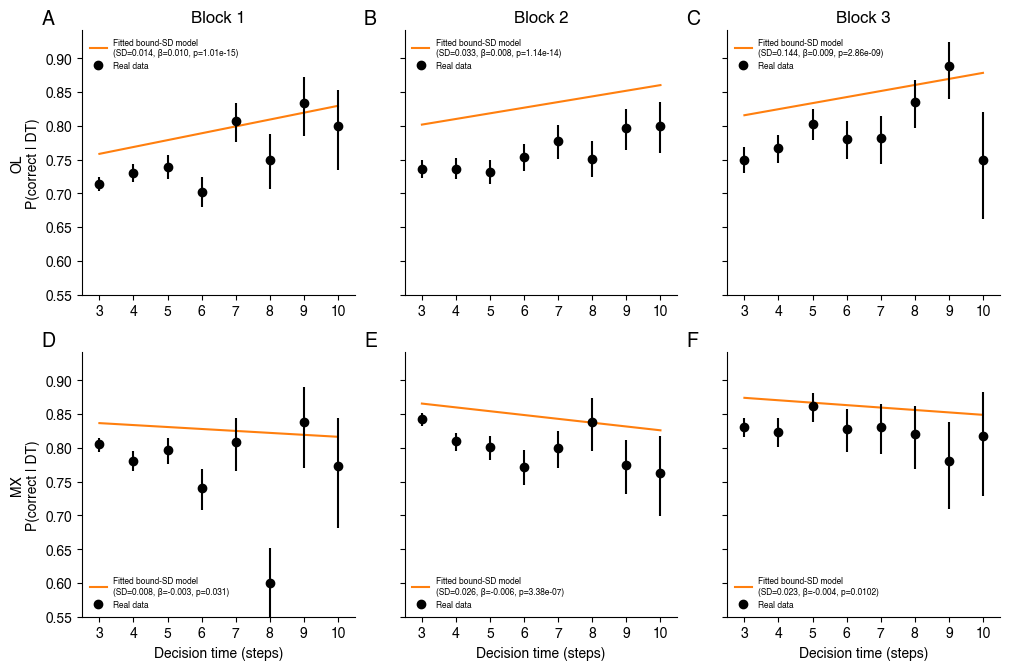

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure03_S05.pdf


In [7]:
COLOR_REAL  = 'k'
COLOR_MODEL = 'tab:orange'

# Shared y-axis limits across all tasks/blocks so panels are directly comparable.
_all_acc = []
for task, _, _ in TASKS:
    for block in BLOCKS:
        r = caf_results[(task, block)]
        for df in (r['df_real'], r['df_model']):
            n, k = dt_counts(df, DT_VALS)
            ok = n > 0
            _all_acc.append(k[ok] / n[ok])
_all_acc = np.concatenate(_all_acc)
CAF_YLIM = (max(0.0, np.nanmin(_all_acc) - 0.05), min(1.02, np.nanmax(_all_acc) + 0.05))

TASK_ROWS = [('OL', 'upper left'), ('MX', 'lower left')]

fig, axs = plt.subplots(2, len(BLOCKS), figsize=(3.4 * len(BLOCKS), 6.8), sharey=True)

for i, (task, legend_loc) in enumerate(TASK_ROWS):
    for j, block in enumerate(BLOCKS):
        ax = axs[i, j]
        r = caf_results[(task, block)]

        ax.axhline(0.5, color='k', linestyle=':', linewidth=1, zorder=0)

        n, k = dt_counts(r['df_real'], DT_VALS)
        acc = k / n
        clo, chi = clopper_pearson(k, n)
        ax.errorbar(DT_VALS, acc, yerr=[acc - clo, chi - acc],
                    fmt='o', color=COLOR_REAL, markerfacecolor=COLOR_REAL, capsize=0,
                    linewidth=0, elinewidth=1.5, markersize=6, zorder=3, label='Real data')

        s = r['stats']
        x_line = np.array([DT_VALS[0], DT_VALS[-1]])
        y_line = s['intercept'] + s['slope'] * x_line
        ax.plot(x_line, y_line, '-', color=COLOR_MODEL, linewidth=1.5, zorder=2,
                 label=f"Fitted bound-SD model\n(SD={r['sd_fit']:.3f}, "
                       f"β={s['slope']:.3f}, p={s['p']:.3g})")

        ax.set_xlim(DT_VALS[0] - 0.5, DT_VALS[-1] + 0.5)
        ax.set_ylim(*CAF_YLIM)
        ax.set_xticks(DT_VALS)
        if i == 0:
            ax.set_title(f'Block {block}')
        if i == len(TASK_ROWS) - 1:
            ax.set_xlabel('Decision time (steps)')
        if j == 0:
            ax.set_ylabel(f'{task}\nP(correct | DT)')
        ax.legend(loc=legend_loc, fontsize=6, frameon=False)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        add_panel_label(ax, chr(65 + i * len(BLOCKS) + j))

plt.tight_layout()
out = FIGURES_DIR / 'Figure03_S05.pdf'
fig.savefig(out, dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out}')